# testing model context using large ensembles and piControl

In [2]:
import warnings
warnings.filterwarnings('ignore')

In [3]:
import numpy as np
import os
import xarray as xr
import xcdat as xc

In [4]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.ticker as mticker
import pandas as pd

In [5]:
import netCDF4
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

ERROR 1: PROJ: proj_create_from_database: Open of /g/data/xp65/public/./apps/med_conda/envs/analysis3-25.09/share/proj failed


In [6]:
import cmocean
from scipy import stats

In [7]:
mpl.rcParams['font.family'] = 'Droid Sans'
mpl.rcParams['font.size'] = 14
# Edit axes parameters
mpl.rcParams['axes.linewidth'] = 0.8
# Tick properties
mpl.rcParams['xtick.major.size'] = 5
mpl.rcParams['xtick.minor.size'] = 3
mpl.rcParams['xtick.major.width'] = 1
mpl.rcParams['xtick.direction'] = 'out'
mpl.rcParams['ytick.major.size'] = 5
mpl.rcParams['ytick.minor.size'] = 3
mpl.rcParams['ytick.major.width'] = 1
mpl.rcParams['ytick.direction'] = 'out'

In [8]:
def plot_decorator():
    ax = plt.gca()
    
    # Minor ticks
    # ax.minorticks_on()
    # plt.tick_params(which='minor', axis='x', bottom=False)
    
    # Grid (light, behind data)
    ax.grid(color='gray', lw=0.4, alpha=0.1)
    
    # Remove top/right spines (Nature style)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Tight layout
    # plt.tight_layout()

In [9]:
from matplotlib.colors import BoundaryNorm as BM
# from matplotlib.colors import LogNorm as LM
import matplotlib.patches as mpatches

In [10]:
import regionmask

In [11]:
def plot_background(ax, draw_labels=False, draw_ipcc_regions=False):
    ax.add_feature(cfeature.COASTLINE, alpha=0.9, lw=1.1)
    # ax.set_global()
    # ax.add_feature(cfeature.LAND, color='lightgray')
    # ax.add_feature(cfeature.OCEAN, color='lightgray')
    gl = ax.gridlines(draw_labels=draw_labels,
                      linewidth=1, color='gray', alpha=0.01, linestyle='--')
    gl.top_labels = False
    # gl.left_labels = False
    # gl.bottom_labels = False
    gl.right_labels = False
    gl.xlines = False
    # gl.xlocator = mticker.FixedLocator([-180, -45, 0, 45, 180])
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {'size': 10, 'color': 'k'}
    gl.ylabel_style = {'size': 10, 'color': 'k'}
    if draw_ipcc_regions:
        ar6_reg = regionmask.defined_regions.ar6.land

        # Plot the region boundaries, passing the same 'ax'
        # Use 'line_kws' to customize line properties (color, thickness, etc.)
        ar6_reg.plot_regions(
            ax=ax,
            line_kws=dict(color='black', lw=1.0, alpha=0.4),
            text_kws=dict(fontsize=8, color='k'), # Set to True to add text labels for regions
            add_label=False, # Set to True to add text labels for regions
        )
    return ax




def plot_maps(x, y, z, titles, labels, cmap, levels, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.Robinson(central_longitude=160), 
            cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=False, subplot_kw={'projection':proj})
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
        if auto_aspect:
            ax.set_aspect('auto')
        else:
            continue
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
        if draw_winds:
            wind_separation = 5
            q = axlist[i].quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd[i][::wind_separation, ::wind_separation], v_wnd[i][::wind_separation, ::wind_separation], scale=wind_scale, color='k', pivot='middle', transform=ccrs.PlateCarree())
            qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
            qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
        if draw_contour:
            axlist[i].contour(x, y, contour_data[i], cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            if hatch_type == 'insig':
                pval_plot = np.ma.masked_less_equal(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='///', transform = ccrs.PlateCarree(central_longitude=0))
                # pval_plot = xr.where(pval[i] > 0.05, True, False)
                # axlist[i].scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker='.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
            elif hatch_type == 'sig':
                pval_plot = np.ma.masked_greater(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...', transform = ccrs.PlateCarree(central_longitude=0))
                # pval_plot = xr.where(pval[i] <= 0.05, True, False)
                # axlist[i].scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker='.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
        axlist[i].set_title(titles[i], fontdict={'fontsize':14})
        axlist[i].text(0.01, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
        if add_patch:
            # axlist[i].add_patch(mpatches.Rectangle(xy=[120, -65], width=170, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[250, -30], width=40, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, 60], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, -80], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
        if add_patch_extra:
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        fig.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])



def plot_single_map(x, y, z, title, label, cmap, levels, add_sign=False, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
                figsize=(12,4), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.Robinson(central_longitude=160), 
                cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig = plt.figure(figsize=figsize)
    ax = plt.axes(projection=proj)
    plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
    if auto_aspect:
        ax.set_aspect('auto')
    
    cf=ax.contourf(x, y, z, cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
    if draw_winds:
        wind_separation = 5
        q = ax.quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd.to_numpy()[::wind_separation, ::wind_separation], v_wnd.to_numpy()[::wind_separation, ::wind_separation], scale=wind_scale, \
        color='k', transform=ccrs.PlateCarree())
        qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
        qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
    if draw_contour:
        ax.contour(x, y, contour_data, cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
    if land_mask_list:
        ax.add_feature(cfeature.LAND, color = 'k', zorder=1)
    if add_sign:
        if hatch_type == 'insig':
            pval_plot = np.ma.masked_less_equal(pval, 0.05)
            ax.pcolor(x, y, pval_plot, alpha = 0., hatch='//', transform = ccrs.PlateCarree(central_longitude=0))
            # pval_plot = xr.where(pval > 0.05, True, False)
            # ax.scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker = '.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
        elif hatch_type == 'sig':
            pval_plot = np.ma.masked_greater(pval, 0.05)
            ax.pcolor(x, y, pval_plot, alpha = 0., hatch='..', transform = ccrs.PlateCarree(central_longitude=0))
            # pval_plot = xr.where(pval <= 0.05, True, False)
            # ax.scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker = '.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
    ax.set_title(title, fontdict={'fontsize':14})
    ax.text(0.01, 1.05, label, size=16, fontweight='bold', transform=ax.transAxes)
    if add_patch:
        ax.add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
    
    if add_patch_extra:
        ax.add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        plt.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = ax, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])

In [12]:
def plot_maps_no_proj(x, y, z, titles, labels, cmap, levels, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False, add_patch_extra=False, hatch_type = 'insig', 
            cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_colorbar=True, auto_aspect=False, draw_clabel=False):

    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=False, sharex=True, sharey=True)
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        if auto_aspect:
            ax.set_aspect('auto')
        else:
            continue
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, levels=levels, extend='both')
        if draw_winds:
            wind_separation = 5
            q = axlist[i].quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd[i][::wind_separation, ::wind_separation], v_wnd[i][::wind_separation, ::wind_separation], scale=wind_scale, color='k', pivot='middle')
    
            qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
            qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
        if draw_contour:
            cs = axlist[i].contour(x, y, contour_data[i], cmap = None, levels=contour_levels, colors=contour_colors, alpha=0.5)
            if draw_clabel:
                axlist[i].clabel(cs, inline=True, fontsize=8)
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            if hatch_type == 'insig':
                pval_plot = np.ma.masked_less_equal(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...')
            elif hatch_type == 'sig':
                pval_plot = np.ma.masked_greater(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...')
        axlist[i].set_title(titles[i], fontdict={'fontsize':14})
        axlist[i].text(0.1, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        fig.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])
    return fig, axlist

In [13]:
import sys

In [14]:
# sys.path.append('./PhD/enso_teleconnection_robustness/')

In [15]:
from functions import preproc_funcs as funcs

In [16]:
ts_pic = xr.open_dataset('/g/data/if69/as8561/data/piControl_data/ts_pic.nc').sel(model = 'ACCESS-ESM1-5').dropna('time')
ts_pic_anom = funcs.calc_anom(ts_pic, ts_pic)

pr_pic = xr.open_dataset('/g/data/if69/as8561/data/piControl_data/pr_pic.nc').sel(model = 'ACCESS-ESM1-5').dropna('time')
pr_pic_anom = funcs.calc_anom(pr_pic, pr_pic)

In [17]:
ts_ssp5 = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens_40_member/ACCESS-ESM1-5_ssp5_ts_original.nc')
ts_ssp5_anom = funcs.calc_anom_annual(ts_ssp5, ts_pic)

pr_ssp5 = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens_40_member/ACCESS-ESM1-5_ssp5_pr_original.nc')
pr_ssp5_anom = funcs.calc_anom_annual(pr_ssp5, pr_pic)

In [18]:
ts_ssp2_anom = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens_40_member/ACCESS-ESM1-5_ssp2_ts.nc')
# ts_ssp2_anom = funcs.calc_anom_annual(ts_ssp2, ts_pic)

pr_ssp2_anom = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens_40_member/ACCESS-ESM1-5_ssp2_pr.nc')
# pr_ssp2_anom = funcs.calc_anom_annual(pr_ssp2, pr_pic)

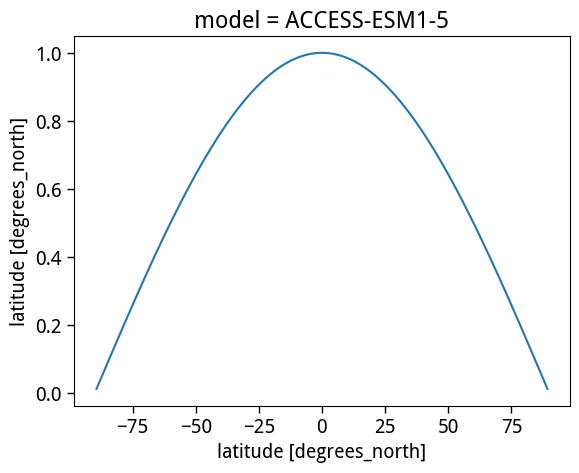

In [19]:
model_weights = np.cos(np.deg2rad(ts_pic.lat))
model_weights.name = 'weights'
model_weights.plot()

In [20]:
nino34_pic = ts_pic_anom.ts.sel(lat = slice(-5, 5), lon = slice(-170+360, -120+360)).weighted(model_weights).mean(('lat', 'lon'))

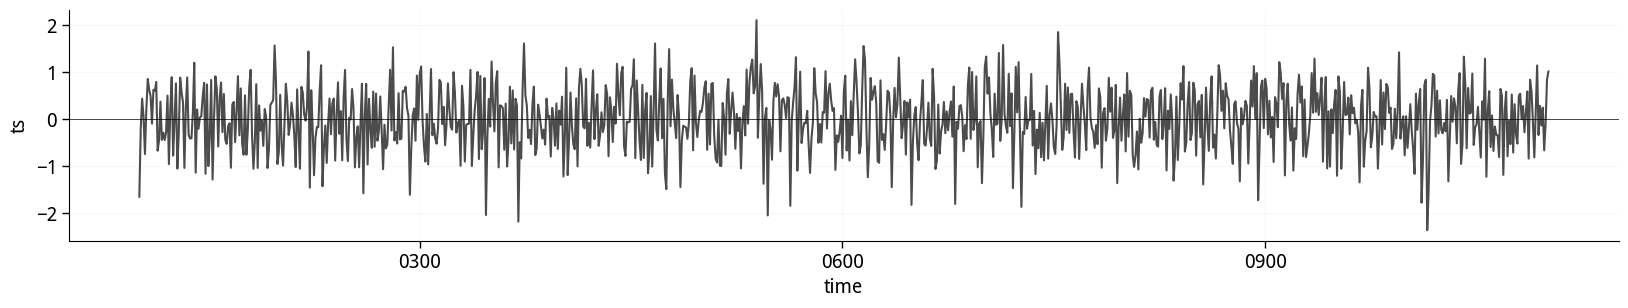

In [21]:
plt.figure(figsize=(20,3))
nino34_pic.plot(color='k', alpha=0.7)
plt.axhline(color='k', lw=0.5)
plot_decorator()

In [22]:
nino34_ssp5 = funcs.detrend_rolling_window(ts_ssp5_anom.ts, window_size=15).sel(lat = slice(-5, 5), lon = slice(-170+360, -120+360)).weighted(model_weights).mean(('lat', 'lon'))
nino34_ssp2 = funcs.detrend_rolling_window(ts_ssp2_anom.ts, window_size=15).sel(lat = slice(-5, 5), lon = slice(-170+360, -120+360)).weighted(model_weights).mean(('lat', 'lon'))

In [23]:
ts_ssp5_det = funcs.detrend_rolling_window(ts_ssp5_anom.ts, window_size=15)
pr_ssp5_det = funcs.detrend_rolling_window(pr_ssp5_anom.pr, window_size=15)
pr_ssp2_det = funcs.detrend_rolling_window(pr_ssp2_anom.pr, window_size=15)

In [24]:
pr_pic_std = pr_pic_anom/pr_pic_anom.std('time')
pr_ssp5_std = pr_ssp5_det/pr_ssp5_det.std('time')
pr_ssp2_std = pr_ssp2_det/pr_ssp2_det.std('time')

In [25]:

from tqdm.auto import tqdm

In [26]:
def calc_tele_diversity(precip, nino34, duration=30, gap=2):

    nt = precip.sizes["time"]
    indices = list(range(0, nt - duration, gap))

    regr_list, corr_list, pval_list = [], [], []
    ey = []

    for i in tqdm(indices, desc="Computing teleconnections"):

        x = nino34.isel(time=slice(i, i+duration))
        y = precip.isel(time=slice(i, i+duration))

        slope, corr, pval = funcs.get_all_metrics(x, y, dim="time")

        regr_list.append(slope.data)
        corr_list.append(corr.data)
        pval_list.append(pval.data)

        ey.append(int(nino34.time.dt.year[i + duration]))

    return xr.Dataset(
        dict(
            regr=("ey lat lon".split(), np.stack(regr_list)),
            corr=("ey lat lon".split(), np.stack(corr_list)),
            pval=("ey lat lon".split(), np.stack(pval_list)),
        ),
        coords=dict(
            lat=precip.lat,
            lon=precip.lon,
            ey=("ey", ey),
        ),
    )


In [27]:
pr_regr_30_pic = calc_tele_diversity(pr_pic_std.pr, nino34_pic, duration=30, gap=30)

Computing teleconnections:   0%|          | 0/33 [00:00<?, ?it/s]

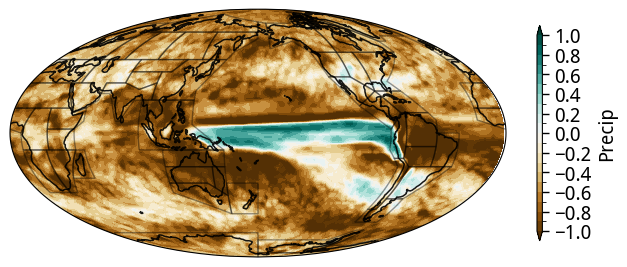

In [28]:
zz = pr_regr_30_pic.regr.min('ey')
xx, yy = np.meshgrid(zz.lon, zz.lat)

plot_single_map(xx, yy, zz, title='', label='', cmap='BrBG', levels=np.linspace(-1, 1, 21), add_sign=False, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
                figsize=(8,4), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.Mollweide(central_longitude=180), 
                cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=True, auto_aspect=False)

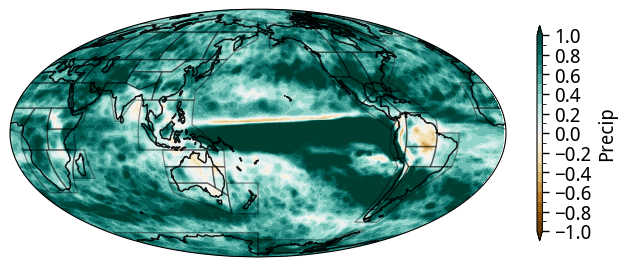

In [29]:
zz = pr_regr_30_pic.regr.max('ey')
xx, yy = np.meshgrid(zz.lon, zz.lat)

plot_single_map(xx, yy, zz, title='', label='', cmap='BrBG', levels=np.linspace(-1, 1, 21), add_sign=False, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
                figsize=(8,4), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.Mollweide(central_longitude=180), 
                cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=True, auto_aspect=False)

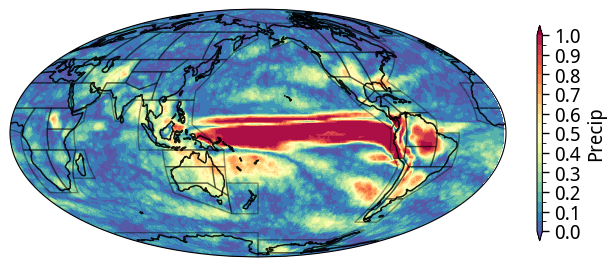

In [30]:
zz = (pr_regr_30_pic.pval.where(pr_regr_30_pic.pval < 0.05).count('ey')/pr_regr_30_pic.pval.count('ey'))
xx, yy = np.meshgrid(zz.lon, zz.lat)

plot_single_map(xx, yy, zz, title='', label='', cmap='Spectral_r', levels=np.linspace(0, 1, 21), add_sign=False, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
                figsize=(8,4), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.Mollweide(central_longitude=180), 
                cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=True, auto_aspect=False)


In [31]:
# pr_regr_30_pic.to_netcdf('/g/data/if69/as8561/data/enso_tele_robustness/pr_regr_30_pic_overlapping.nc')

In [32]:
pr_regr_30_pic_overlap = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/pr_regr_30_pic_overlapping.nc')

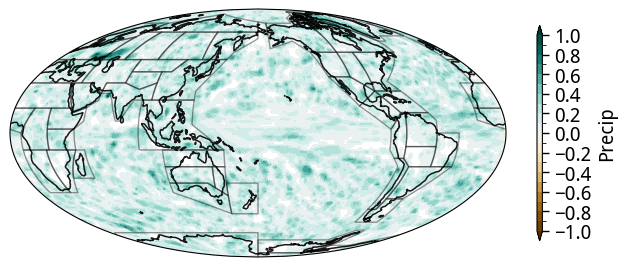

In [34]:
zz = pr_regr_30_pic.regr.min('ey') - pr_regr_30_pic_overlap.regr.min('ey')
xx, yy = np.meshgrid(zz.lon, zz.lat)

plot_single_map(xx, yy, zz, title='', label='', cmap='BrBG', levels=np.linspace(-1.0, 1.0, 21), add_sign=False, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
                figsize=(8,4), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.Mollweide(central_longitude=180), 
                cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=True, auto_aspect=False)

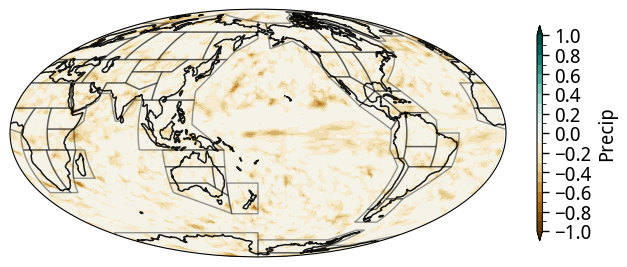

In [35]:
zz = pr_regr_30_pic.regr.max('ey') - pr_regr_30_pic_overlap.regr.max('ey')
xx, yy = np.meshgrid(zz.lon, zz.lat)

plot_single_map(xx, yy, zz, title='', label='', cmap='BrBG', levels=np.linspace(-1.0, 1.0, 21), add_sign=False, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
                figsize=(8,4), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.Mollweide(central_longitude=180), 
                cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=True, auto_aspect=False)

In [36]:
pr_ssp2_std['model'] = nino34_ssp2.model

In [37]:
hist_30 = funcs.get_all_metrics(nino34_ssp5.sel(time = slice('1900', '1930')), pr_ssp5_std.sel(time = slice('1900', '1930')), dim='time')
print('done')
fut_30_ssp5 = funcs.get_all_metrics(nino34_ssp5.sel(time = slice('2070', '2100')), pr_ssp5_std.sel(time = slice('2070', '2100')), dim='time')
print('done')
fut_30_ssp2 = funcs.get_all_metrics(nino34_ssp2.sel(time = slice('2070', '2100')), pr_ssp2_std.sel(time = slice('2070', '2100')), dim='time')
print('done')

done
done
done


In [38]:
hist_full = funcs.get_all_metrics(nino34_ssp5.sel(time = slice('1900', '2014')), pr_ssp5_std.sel(time = slice('1900', '2014')), dim='time')
print('done')

done


In [39]:
pr_regr_30_rean = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/pr_regr_30_rean.nc')
pr_regr_30_obs = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/pr_regr_30.nc')

In [40]:
land_mask_rean = regionmask.defined_regions.natural_earth_v5_0_0.land_10.mask_3D(pr_regr_30_rean)
ar6_mask_rean = regionmask.defined_regions.ar6.land.mask_3D(pr_regr_30_rean.where(land_mask_rean))

In [41]:
land_mask_obs = regionmask.defined_regions.natural_earth_v5_0_0.land_10.mask_3D(pr_regr_30_obs)
ar6_mask_obs = regionmask.defined_regions.ar6.land.mask_3D(pr_regr_30_obs.where(land_mask_obs))

In [42]:
land_mask_model = regionmask.defined_regions.natural_earth_v5_0_0.land_10.mask_3D(hist_30[0])
ar6_mask_model = regionmask.defined_regions.ar6.land.mask_3D(hist_30[0].where(land_mask_model))

In [43]:
obs_weights = np.cos(np.deg2rad(pr_regr_30_obs.lat))
rean_weights = np.cos(np.deg2rad(pr_regr_30_rean.lat))

In [44]:
analysis_region=[16]

obs_range = pr_regr_30_obs.regr.where(ar6_mask_obs.isel(region=analysis_region)).weighted(obs_weights).mean(('lat', 'lon')).mean('region')
rean_range = pr_regr_30_rean.regr.where(ar6_mask_rean.isel(region=analysis_region)).weighted(rean_weights).mean(('lat', 'lon')).mean('region')

pic_range = pr_regr_30_pic.regr.where(ar6_mask_model.isel(region=analysis_region)).weighted(model_weights).mean(('lat', 'lon')).mean('region')
pic_range_overlap = pr_regr_30_pic_overlap.regr.where(ar6_mask_model.isel(region=analysis_region)).weighted(model_weights).mean(('lat', 'lon')).mean('region')

hist_range = hist_30[0].where(ar6_mask_model.isel(region=analysis_region)).weighted(model_weights).mean(('lat', 'lon')).mean('region')
hist_range_full = hist_full[0].where(ar6_mask_model.isel(region=analysis_region)).weighted(model_weights).mean(('lat', 'lon')).mean('region')

fut2_range = fut_30_ssp2[0].where(ar6_mask_model.isel(region=analysis_region)).weighted(model_weights).mean(('lat', 'lon')).mean('region')
fut5_range = fut_30_ssp5[0].where(ar6_mask_model.isel(region=analysis_region)).weighted(model_weights).mean(('lat', 'lon')).mean('region')

Text(0.5, 1.0, "['N.Europe']")

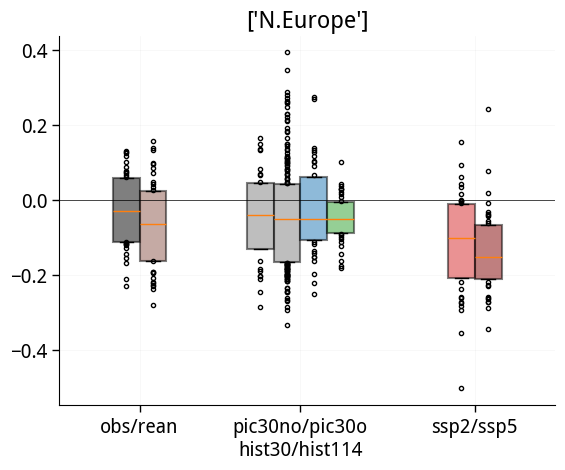

In [45]:
# plt.boxplot([obs_range.regr, rean_range.regr, pic_range.regr, hist_range, fut2_range, fut5_range], whis=[5,95])
plt.boxplot([obs_range, rean_range, pic_range, pic_range_overlap, hist_range, hist_range_full, fut2_range, fut5_range], whis=[25, 75], patch_artist=True, positions=[0, 0.2, 1,1.2,1.4,1.6, 2.5,2.7], flierprops=dict(marker='.'), widths=0.2)

colors = ['black', 'tab:brown', 'tab:gray', 'tab:gray', 'tab:blue', 'tab:green', 'tab:red', 'maroon']
for patch, color in zip(plt.gca().patches, colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.5)
    patch.set_edgecolor('black')
    patch.set_linewidth(1.5)

plt.gca().set_xticks([0.1, 1.3, 2.6])
plt.gca().set_xticklabels(['obs/rean', 'pic30no/pic30o\nhist30/hist114', 'ssp2/ssp5'])
plot_decorator()
plt.axhline(0.0, color='k', lw=0.5)
plt.title(str(ar6_mask_obs.isel(region=analysis_region).names.values))
# plt.axhline(obs_range.mean('ey'), color='k', lw=1.5)
# plt.axhline(rean_range.mean('ey'), color='k', lw=1.5)

In [46]:
analysis_region=[39]

obs_range = pr_regr_30_obs.regr.where(ar6_mask_obs.isel(region=analysis_region)).weighted(obs_weights).mean(('lat', 'lon')).mean('region')
rean_range = pr_regr_30_rean.regr.where(ar6_mask_rean.isel(region=analysis_region)).weighted(rean_weights).mean(('lat', 'lon')).mean('region')

pic_range = pr_regr_30_pic.regr.where(ar6_mask_model.isel(region=analysis_region)).weighted(model_weights).mean(('lat', 'lon')).mean('region')
pic_range_overlap = pr_regr_30_pic_overlap.regr.where(ar6_mask_model.isel(region=analysis_region)).weighted(model_weights).mean(('lat', 'lon')).mean('region')

hist_range = hist_30[0].where(ar6_mask_model.isel(region=analysis_region)).weighted(model_weights).mean(('lat', 'lon')).mean('region')
hist_range_full = hist_full[0].where(ar6_mask_model.isel(region=analysis_region)).weighted(model_weights).mean(('lat', 'lon')).mean('region')

fut2_range = fut_30_ssp2[0].where(ar6_mask_model.isel(region=analysis_region)).weighted(model_weights).mean(('lat', 'lon')).mean('region')
fut5_range = fut_30_ssp5[0].where(ar6_mask_model.isel(region=analysis_region)).weighted(model_weights).mean(('lat', 'lon')).mean('region')

Text(0.5, 1.0, "['N.Australia']")

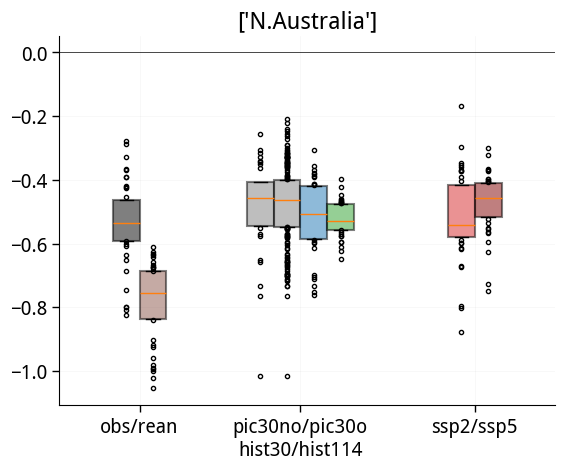

In [47]:
# plt.boxplot([obs_range.regr, rean_range.regr, pic_range.regr, hist_range, fut2_range, fut5_range], whis=[5,95])
plt.boxplot([obs_range, rean_range, pic_range, pic_range_overlap, hist_range, hist_range_full, fut2_range, fut5_range], whis=[25, 75], patch_artist=True, positions=[0, 0.2, 1,1.2,1.4,1.6, 2.5,2.7], flierprops=dict(marker='.'), widths=0.2)

colors = ['black', 'tab:brown', 'tab:gray', 'tab:gray', 'tab:blue', 'tab:green', 'tab:red', 'maroon']
for patch, color in zip(plt.gca().patches, colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.5)
    patch.set_edgecolor('black')
    patch.set_linewidth(1.5)

plt.gca().set_xticks([0.1, 1.3, 2.6])
plt.gca().set_xticklabels(['obs/rean', 'pic30no/pic30o\nhist30/hist114', 'ssp2/ssp5'])
plot_decorator()
plt.axhline(0.0, color='k', lw=0.5)
plt.title(str(ar6_mask_obs.isel(region=analysis_region).names.values))
# plt.axhline(obs_range.mean('ey'), color='k', lw=1.5)
# plt.axhline(rean_range.mean('ey'), color='k', lw=1.5)

In [48]:
analysis_region=[19]

obs_range = pr_regr_30_obs.regr.where(ar6_mask_obs.isel(region=analysis_region)).weighted(obs_weights).mean(('lat', 'lon')).mean('region')
rean_range = pr_regr_30_rean.regr.where(ar6_mask_rean.isel(region=analysis_region)).weighted(rean_weights).mean(('lat', 'lon')).mean('region')

pic_range = pr_regr_30_pic.regr.where(ar6_mask_model.isel(region=analysis_region)).weighted(model_weights).mean(('lat', 'lon')).mean('region')
pic_range_overlap = pr_regr_30_pic_overlap.regr.where(ar6_mask_model.isel(region=analysis_region)).weighted(model_weights).mean(('lat', 'lon')).mean('region')

hist_range = hist_30[0].where(ar6_mask_model.isel(region=analysis_region)).weighted(model_weights).mean(('lat', 'lon')).mean('region')
hist_range_full = hist_full[0].where(ar6_mask_model.isel(region=analysis_region)).weighted(model_weights).mean(('lat', 'lon')).mean('region')

fut2_range = fut_30_ssp2[0].where(ar6_mask_model.isel(region=analysis_region)).weighted(model_weights).mean(('lat', 'lon')).mean('region')
fut5_range = fut_30_ssp5[0].where(ar6_mask_model.isel(region=analysis_region)).weighted(model_weights).mean(('lat', 'lon')).mean('region')

Text(0.5, 1.0, "['Mediterranean']")

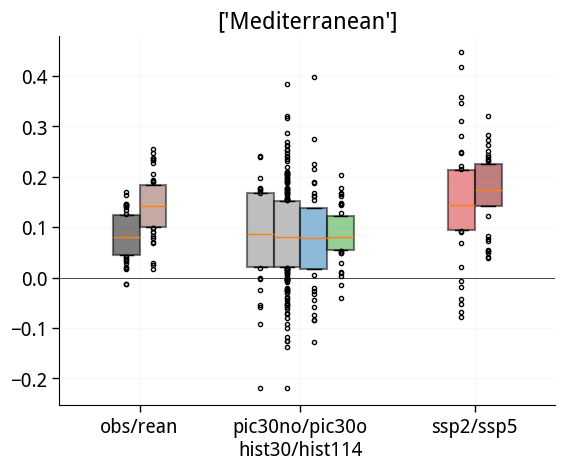

In [49]:
# plt.boxplot([obs_range.regr, rean_range.regr, pic_range.regr, hist_range, fut2_range, fut5_range], whis=[5,95])
plt.boxplot([obs_range, rean_range, pic_range, pic_range_overlap, hist_range, hist_range_full, fut2_range, fut5_range], whis=[25, 75], patch_artist=True, positions=[0, 0.2, 1,1.2,1.4,1.6, 2.5,2.7], flierprops=dict(marker='.'), widths=0.2)

colors = ['black', 'tab:brown', 'tab:gray', 'tab:gray', 'tab:blue', 'tab:green', 'tab:red', 'maroon']
for patch, color in zip(plt.gca().patches, colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.5)
    patch.set_edgecolor('black')
    patch.set_linewidth(1.5)

plt.gca().set_xticks([0.1, 1.3, 2.6])
plt.gca().set_xticklabels(['obs/rean', 'pic30no/pic30o\nhist30/hist114', 'ssp2/ssp5'])
plot_decorator()
plt.axhline(0.0, color='k', lw=0.5)
plt.title(str(ar6_mask_obs.isel(region=analysis_region).names.values))
# plt.axhline(obs_range.mean('ey'), color='k', lw=1.5)
# plt.axhline(rean_range.mean('ey'), color='k', lw=1.5)

In [125]:
analysis_region=[12]

obs_range = pr_regr_30_obs.regr.where(ar6_mask_obs.isel(region=analysis_region)).weighted(obs_weights).mean(('lat', 'lon')).mean('region')
rean_range = pr_regr_30_rean.regr.where(ar6_mask_rean.isel(region=analysis_region)).weighted(rean_weights).mean(('lat', 'lon')).mean('region')

pic_range = pr_regr_30_pic.regr.where(ar6_mask_model.isel(region=analysis_region)).weighted(model_weights).mean(('lat', 'lon')).mean('region')
pic_range_overlap = pr_regr_30_pic_overlap.regr.where(ar6_mask_model.isel(region=analysis_region)).weighted(model_weights).mean(('lat', 'lon')).mean('region')

hist_range = hist_30[0].where(ar6_mask_model.isel(region=analysis_region)).weighted(model_weights).mean(('lat', 'lon')).mean('region')
hist_range_full = hist_full[0].where(ar6_mask_model.isel(region=analysis_region)).weighted(model_weights).mean(('lat', 'lon')).mean('region')

fut2_range = fut_30_ssp2[0].where(ar6_mask_model.isel(region=analysis_region)).weighted(model_weights).mean(('lat', 'lon')).mean('region')
fut5_range = fut_30_ssp5[0].where(ar6_mask_model.isel(region=analysis_region)).weighted(model_weights).mean(('lat', 'lon')).mean('region')

Text(0.5, 1.0, "['South-American-Monsoon']")

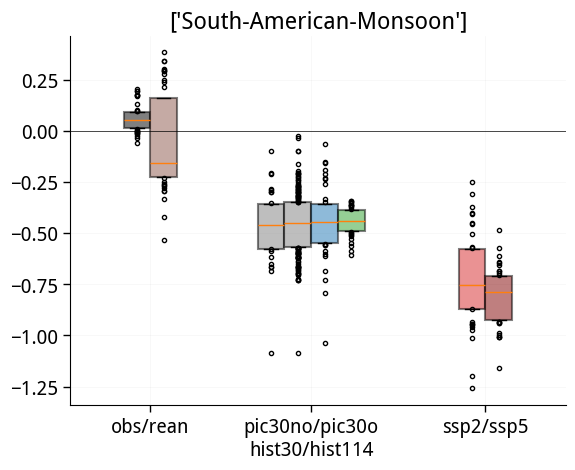

In [126]:
# plt.boxplot([obs_range.regr, rean_range.regr, pic_range.regr, hist_range, fut2_range, fut5_range], whis=[5,95])
plt.boxplot([obs_range, rean_range, pic_range, pic_range_overlap, hist_range, hist_range_full, fut2_range, fut5_range], whis=[25, 75], patch_artist=True, positions=[0, 0.2, 1,1.2,1.4,1.6, 2.5,2.7], flierprops=dict(marker='.'), widths=0.2)

colors = ['black', 'tab:brown', 'tab:gray', 'tab:gray', 'tab:blue', 'tab:green', 'tab:red', 'maroon']
for patch, color in zip(plt.gca().patches, colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.5)
    patch.set_edgecolor('black')
    patch.set_linewidth(1.5)

plt.gca().set_xticks([0.1, 1.3, 2.6])
plt.gca().set_xticklabels(['obs/rean', 'pic30no/pic30o\nhist30/hist114', 'ssp2/ssp5'])
plot_decorator()
plt.axhline(0.0, color='k', lw=0.5)
plt.title(str(ar6_mask_obs.isel(region=analysis_region).names.values))
# plt.axhline(obs_range.mean('ey'), color='k', lw=1.5)
# plt.axhline(rean_range.mean('ey'), color='k', lw=1.5)

In [123]:
# create a dataframe with each region having all vavluves of obs, rean, pic, hist, fut2, fut5

obs_arr = np.empty((len(ar6_mask_obs.region)))
rean_arr = np.empty_like(obs_arr)
pic_arr = np.empty((len(ar6_mask_rean.region)))
hist_arr = np.empty((len(ar6_mask_model.region)))
hist_full_arr = np.empty_like(hist_arr)
fut2_arr = np.empty_like(hist_arr)
fut5_arr = np.empty_like(hist_arr)

for analysis_region in range(len(ar6_mask_obs.region)):
    obs_arr[analysis_region] = pr_regr_30_obs.regr.where(ar6_mask_obs.isel(region=analysis_region)).weighted(obs_weights).mean(('lat', 'lon')).max('ey')
    rean_arr[analysis_region] = pr_regr_30_rean.regr.where(ar6_mask_rean.isel(region=analysis_region)).weighted(rean_weights).mean(('lat', 'lon')).max('ey')
    pic_arr[analysis_region] = pr_regr_30_pic.regr.where(ar6_mask_model.isel(region=analysis_region)).weighted(model_weights).mean(('lat', 'lon')).max('ey')
    hist_arr[analysis_region] = hist_30[0].where(ar6_mask_model.isel(region=analysis_region)).weighted(model_weights).mean(('lat', 'lon')).max()
    hist_full_arr[analysis_region] = hist_full[0].where(ar6_mask_model.isel(region=analysis_region)).weighted(model_weights).mean(('lat', 'lon')).max()
    fut2_arr[analysis_region] = fut_30_ssp2[0].where(ar6_mask_model.isel(region=analysis_region)).weighted(model_weights).mean(('lat', 'lon')).max()
    fut5_arr[analysis_region] = fut_30_ssp5[0].where(ar6_mask_model.isel(region=analysis_region)).weighted(model_weights).mean(('lat', 'lon')).max()

region_df_max = pd.DataFrame({
    'obs': obs_arr.flatten(),
    'rean': rean_arr.flatten(),
    'pic': pic_arr.flatten(),
    'Hist30': hist_arr.flatten(),
    'Hist114': hist_arr.flatten(),
    'ssp2': fut2_arr.flatten(),
    'ssp5': fut5_arr.flatten()
}, index=ar6_mask_model.region.names.values)

In [122]:
import seaborn as sns

[Text(0, 0.5, ''),
 Text(0, 1.5, ''),
 Text(0, 2.5, ''),
 Text(0, 3.5, ''),
 Text(0, 4.5, ''),
 Text(0, 5.5, ''),
 Text(0, 6.5, ''),
 Text(0, 7.5, ''),
 Text(0, 8.5, ''),
 Text(0, 9.5, ''),
 Text(0, 10.5, ''),
 Text(0, 11.5, ''),
 Text(0, 12.5, ''),
 Text(0, 13.5, ''),
 Text(0, 14.5, ''),
 Text(0, 15.5, ''),
 Text(0, 16.5, ''),
 Text(0, 17.5, ''),
 Text(0, 18.5, ''),
 Text(0, 19.5, ''),
 Text(0, 20.5, ''),
 Text(0, 21.5, ''),
 Text(0, 22.5, ''),
 Text(0, 23.5, ''),
 Text(0, 24.5, ''),
 Text(0, 25.5, ''),
 Text(0, 26.5, ''),
 Text(0, 27.5, ''),
 Text(0, 28.5, ''),
 Text(0, 29.5, ''),
 Text(0, 30.5, ''),
 Text(0, 31.5, ''),
 Text(0, 32.5, ''),
 Text(0, 33.5, ''),
 Text(0, 34.5, ''),
 Text(0, 35.5, ''),
 Text(0, 36.5, ''),
 Text(0, 37.5, ''),
 Text(0, 38.5, ''),
 Text(0, 39.5, ''),
 Text(0, 40.5, ''),
 Text(0, 41.5, ''),
 Text(0, 42.5, ''),
 Text(0, 43.5, ''),
 Text(0, 44.5, ''),
 Text(0, 45.5, '')]

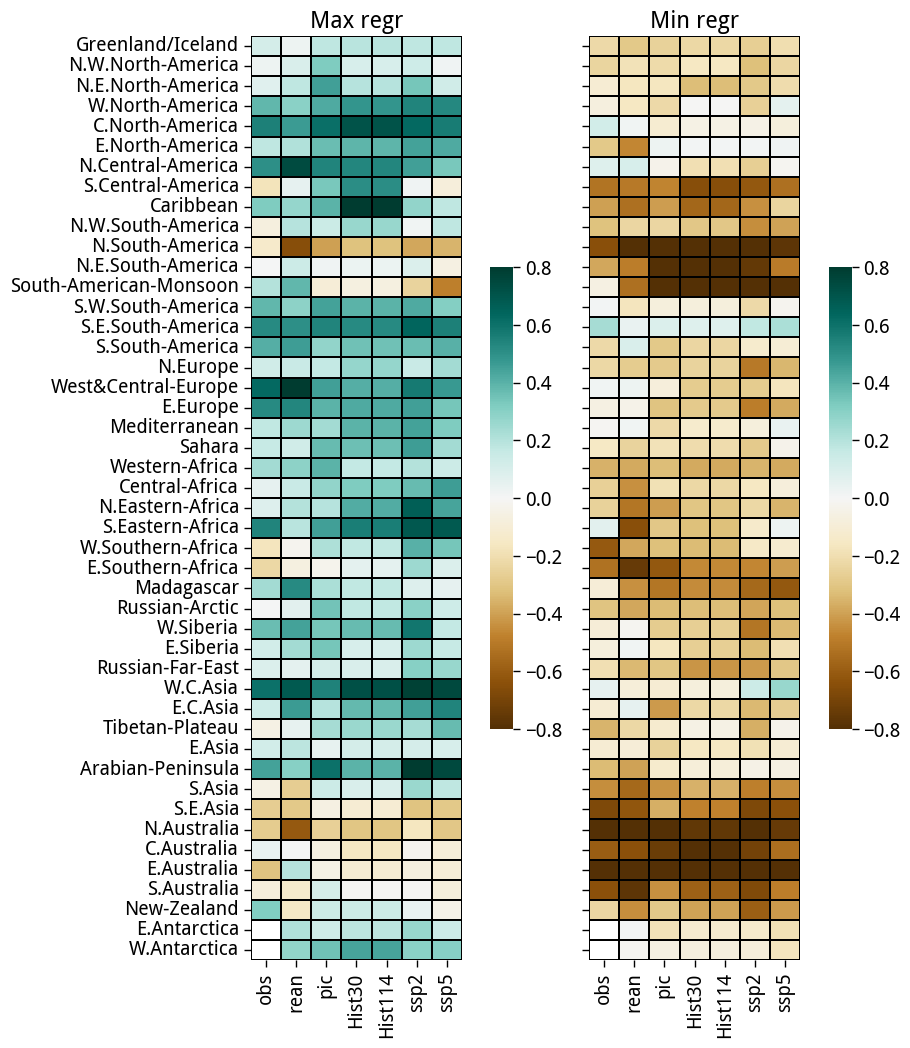

In [127]:
plt.figure(figsize=(8,12))

plt.subplot(121)
sns.heatmap(region_df_max, cmap='BrBG', vmin=-0.8, vmax=0.8, cbar_kws=dict(shrink=0.5, pad=0.1), lw=0.1, linecolor='k')
plt.title('Max regr')

plt.subplot(122)
sns.heatmap(region_df_min, cmap='BrBG', vmin=-0.8, vmax=0.8, cbar_kws=dict(shrink=0.5, pad=0.1), lw=0.1, linecolor='k')
plt.title('Min regr')
plt.ylabel('')
plt.gca().set_yticklabels([])

In [ ]:
p